In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid')
print('Libraries loaded')

Libraries loaded


In [2]:
df = pd.read_csv("../../data/feature_engineering/data/daily_features_all.csv", parse_dates=["date"])
df = df[df.protocol == "morpho"]
print(df.shape)
print(df["whale_id"].value_counts().sort_index())

(2022, 38)
whale_id
W-1      78
W-10    254
W-11    622
W-12     71
W-13    156
W-14    118
W-15      9
W-16     38
W-17      1
W-2     300
W-3     139
W-4      27
W-5      35
W-6      72
W-7      58
W-8      20
W-9      24
Name: count, dtype: int64


shows how many days each whales appears in the dataset including days with no open position

In [3]:
panel = df.dropna(subset=["ltv", "carry_spread", "carry_spread_levered"]).copy()
print(len(panel), len(df))
print(panel["whale_id"].value_counts().sort_index())

1750 2022
whale_id
W-1      77
W-10    253
W-11    622
W-12     70
W-13    144
W-14    113
W-15      8
W-16     37
W-17      1
W-2      88
W-3     139
W-4      26
W-5      34
W-6      38
W-7      58
W-8      19
W-9      23
Name: count, dtype: int64


Drops rows with no `ltv` (a.k.a no open debt that day) and/or missing `carry_spread`/`carry_spread_levered`.
The new counts include only days we can actually cluster.

In [4]:
FEATURES = [
    "ltv", "loop_depth", "distance_to_liq",
    "ltv_vol_7d", "ltv_vol_14d",
    "rebal_freq_7d", "rebal_freq_30d", "days_since_rebalance",
    "ltv_lag_7", "carry_spread", "carry_spread_levered",
]

X = panel[FEATURES].fillna(panel[FEATURES].median())
X.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
ltv,1750.0,0.602,0.379,0.000,0.250,0.815,0.910,0.962
loop_depth,1750.0,7.070,7.011,0.000,1.000,5.000,11.000,26.000
distance_to_liq,1750.0,0.310,0.358,-0.002,0.030,0.087,0.610,0.965
ltv_vol_7d,1750.0,0.016,0.064,0.000,0.000,0.000,0.001,0.503
ltv_vol_14d,1750.0,0.027,0.082,0.000,0.000,0.001,0.005,0.551
rebal_freq_7d,1750.0,1.158,1.600,0.000,0.000,0.000,2.000,7.000
rebal_freq_30d,1750.0,4.453,4.881,0.000,0.000,3.000,7.000,24.000
days_since_rebalance,1750.0,30.687,47.617,0.000,1.000,7.000,39.000,208.000
ltv_lag_7,1750.0,0.620,0.367,0.000,0.259,0.815,0.907,0.962
carry_spread,1750.0,7.240,7.578,-20.867,3.308,4.055,9.109,85.178


The table above shows the stats for each 11 behavioural feature on those active looping days.

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pd.DataFrame(X_scaled, columns=FEATURES).describe().loc[["mean", "std"]].round(3)

,ltv,loop_depth,distance_to_liq,ltv_vol_7d,ltv_vol_14d,rebal_freq_7d,rebal_freq_30d,days_since_rebalance,ltv_lag_7,carry_spread,carry_spread_levered
mean,0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


`StandardScaler` puts all 11 features on the same scale so HDBSCAN doesn't treat - for instance - `loop_depth` (0-26) as more important than `distance_to_liq` (0-1) just because the numbers are bigger.

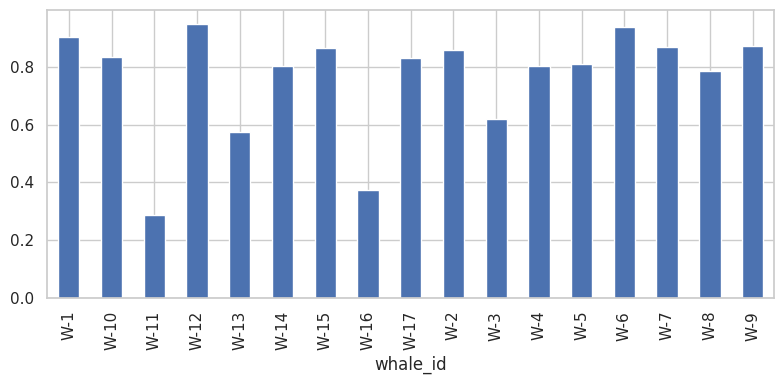

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
panel.groupby("whale_id")["ltv"].mean().sort_index().plot(kind="bar", ax=ax)
plt.tight_layout()
plt.show()

The plot above shows mean LTV per whale on active looping days. W-11 is lowest (~0.29); W-12 and W-6 are highest (~0.95/0.94). W-3 sits mid-range (~0.62) with wide day-to-day spread; W-1 is high (~0.91) but no longer the top of the panel.

check new whales W-7..W-17 on active days (open debt)

In [7]:
NEW = [f"W-{i}" for i in range(7, 18)]
new_whales = df[(df.whale_id.isin(NEW)) & (df.borrow_balance_usd >= 1)]
print(new_whales.groupby("whale_id").agg(
    days=("whale_id", "size"),
    ltv_max=("ltv", "max"),
    hf_min=("health_factor", "min"),
).sort_index())
print()
print(new_whales.loc[new_whales.health_factor < 1, ["whale_id", "date", "ltv", "health_factor", "liquidation_threshold"]])


          days   ltv_max    hf_min
whale_id                          
W-10       253  0.878618  1.041408
W-11       336  0.797804  1.077959
W-12        70  0.954537  1.010961
W-13        88  0.955085  1.010381
W-14       110  0.948473  1.017425
W-15         8  0.917063  0.997751
W-16        20  0.857358  1.067233
W-17         1  0.831781  1.100050
W-7         58  0.888258  1.030107
W-8         19  0.848133  1.078840
W-9         23  0.899082  1.017704

     whale_id       date       ltv  health_factor  liquidation_threshold
1299     W-15 2026-03-01  0.917063       0.997751                  0.915


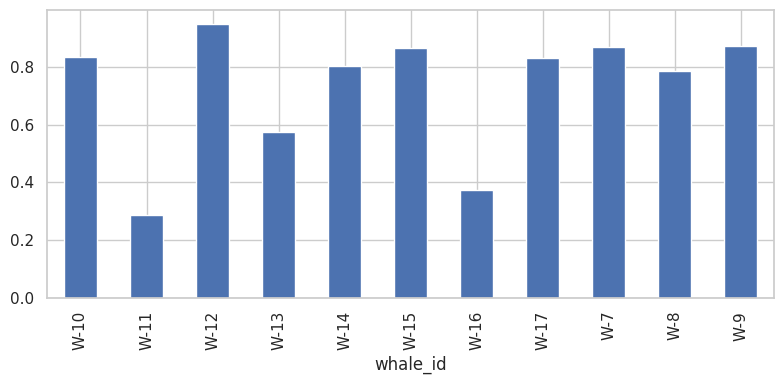

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
panel[panel.whale_id.isin(NEW)].groupby("whale_id")["ltv"].mean().sort_index().plot(kind="bar", ax=ax)
plt.tight_layout()
plt.show()


mean LTV per new whale on active looping days.

### Save features to CSV

In [9]:
panel[["whale_id", "protocol", "date"] + FEATURES].to_csv("panel_cluster_ready.csv", index=False)